# Patrones temporales y asociaciones en variables meteorológicas abiertas del Bajo Cauca
### Simulación reproducible con datos artificiales (NumPy + pandas + SciPy + Matplotlib)



**Docente:** Marcos Julio Cañas Campillo  
**Estudiantes:** Manuel Medina Guerra · Juan Camilo Guerra Mercado · Keren Castro Julio

---



> ⚠️ **Todos los datos de este cuaderno son sintéticos.** Se generan con NumPy/pandas imitando el comportamiento
> esperado de tres fuentes públicas (**IDEAM**, **NASA POWER** y **ERA5**) y de un índice **ONI** de ENSO.
> Ninguna cifra debe interpretarse como un resultado climático real del Bajo Cauca.



**¿Para qué sirve una simulación así?** Como *sembramos* los parámetros verdaderos (tendencia, rezago ENSO, sesgos de cada
fuente, errores de captura), podemos comprobar si el flujo de trabajo propuesto los **recupera**. Es un ensayo general
del procedimiento antes de aplicarlo a datos reales.

### Correspondencia con la propuesta

| Objetivo específico | Sección del cuaderno |
|---|---|
| 1. Caracterizar las fuentes (cobertura, resolución, periodo, vacíos) | 2 y 3 |
| 2. Conjunto depurado con control de calidad y manejo de faltantes | 4 y 5 |
| 3. Tendencia, estacionalidad y variabilidad interanual | 6, 7 y 8 |
| 4. Asociaciones entre variables y con el ONI | 9 y 10 |
| (Metodología) Comparación entre fuentes | 11 |
| 5. Publicar el procedimiento de forma reproducible | 12 y 13 |

## 1. Configuración
Se fija una **semilla** para que cualquier persona obtenga exactamente los mismos datos y resultados.

In [1]:
import sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 2024
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 140)

COLORES = {"IDEAM": "#1b6ca8", "NASA POWER": "#e07a1f", "ERA5": "#2a9d5c"}
VARS = {
    "temp_c":    ("Temperatura media", "°C"),
    "precip_mm": ("Precipitación", "mm/mes"),
    "hr_pct":    ("Humedad relativa", "%"),
}
COLS = list(VARS)

DIR_DATOS = Path("datos_sinteticos"); DIR_DATOS.mkdir(exist_ok=True)
DIR_SALIDAS = Path("salidas");        DIR_SALIDAS.mkdir(exist_ok=True)

## 2. Generación de los datos sintéticos

### 2.1 "Verdad" climática (lo que en la vida real nunca conocemos)
Se construye una serie diaria 1991-2023 con parámetros **conocidos**:

- **Temperatura**: nivel medio cercano a 27.6 °C, ciclo anual suave, **tendencia de +0.025 °C/año** y respuesta al ENSO
  con **3 meses de rezago** (El Niño → más cálido).
- **Precipitación**: régimen **bimodal** (picos abril-mayo y septiembre-noviembre, época seca dic-mar), ocurrencia de
  días lluviosos + cantidades tipo Gamma, **tendencia de −0.2 %/año** y respuesta al ENSO con **2 meses de rezago**
  (El Niño → más seco).
- **Humedad relativa**: depende de la lluvia reciente y (negativamente) de la temperatura. Su tendencia es *indirecta*.
- **ONI**: serie mensual tipo ENSO (persistente y oscilante), estandarizada para que tenga amplitud realista.

In [2]:
PARAMS = dict(
    inicio="1991-01-01", fin="2023-12-31",
    temp_media=27.6, temp_amp=0.7,
    temp_tendencia=0.025,        # °C por año
    temp_enso_coef=0.35,         # °C por unidad de ONI
    temp_enso_rezago=3,          # meses
    precip_anual=2700.0,         # mm/año
    precip_tendencia_pct=-0.2,   # % por año
    precip_enso_coef=-0.12,      # sensibilidad logarítmica por unidad de ONI
    precip_enso_rezago=2,        # meses
    hr_base=78.0,
)

fechas = pd.date_range(PARAMS["inicio"], PARAMS["fin"], freq="D")
meses  = pd.date_range(PARAMS["inicio"], PARAMS["fin"], freq="MS")
n_d, n_m = len(fechas), len(meses)

def ar1(n, phi, sigma):
    '''Ruido AR(1) con desviación estándar marginal sigma.'''
    e = rng.normal(0, sigma * np.sqrt(1 - phi**2), n)
    x = np.empty(n); x[0] = rng.normal(0, sigma)
    for t in range(1, n):
        x[t] = phi * x[t-1] + e[t]
    return x

# --- Índice ONI sintético (mensual) ---------------------------------------
x   = ar1(n_m, 0.94, 1.0)
osc = 0.9 * np.sin(2*np.pi*np.arange(n_m)/(12*3.7) + rng.uniform(0, 2*np.pi))
oni = x + osc
oni = (oni - oni.mean()) / oni.std() * 0.85
oni = pd.Series(oni, index=meses, name="ONI").rolling(3, center=True, min_periods=1).mean()

def oni_diario(k):
    '''ONI con k meses de rezago, expandido a frecuencia diaria.'''
    s = oni.shift(k).bfill()
    return s.reindex(fechas.to_period("M").to_timestamp()).to_numpy()

anios = np.asarray((fechas - fechas[0]).days) / 365.25
doy   = fechas.dayofyear.to_numpy()
mes   = fechas.month.to_numpy()

# --- Temperatura media diaria (°C) ----------------------------------------
T = (PARAMS["temp_media"]
     + PARAMS["temp_amp"] * np.cos(2*np.pi*(doy - 90)/365.25)
     + PARAMS["temp_tendencia"] * anios
     + PARAMS["temp_enso_coef"] * oni_diario(PARAMS["temp_enso_rezago"])
     + ar1(n_d, 0.6, 0.7))

# --- Precipitación diaria (mm) --------------------------------------------
frac = np.array([3.0, 3.5, 5.5, 10, 13, 9, 9, 10, 11, 13, 9.5, 3.5]) / 100   # fracción anual por mes
mm_clim   = PARAMS["precip_anual"] * frac
dias_mes  = fechas.days_in_month.to_numpy()
media_dia = mm_clim[mes - 1] / dias_mes
factor    = (np.exp(PARAMS["precip_enso_coef"] * oni_diario(PARAMS["precip_enso_rezago"]))
             * (1 + PARAMS["precip_tendencia_pct"]/100 * anios))
media_dia = media_dia * factor

p0    = 0.20 + 0.60 * (mm_clim / mm_clim.max())                  # prob. de día lluvioso (climatológica)
p_hum = np.clip(p0[mes - 1] * np.sqrt(factor), 0.05, 0.95)
llueve   = rng.random(n_d) < p_hum
cantidad = rng.gamma(0.8, (media_dia / p_hum) / 0.8)             # media = media_dia / p_hum
P = np.where(llueve, cantidad, 0.0).clip(max=300)

# --- Humedad relativa diaria (%) ------------------------------------------
P3 = pd.Series(P).rolling(3, min_periods=1).mean().to_numpy()
HR = (PARAMS["hr_base"] + 1.5*np.cos(2*np.pi*(doy - 300)/365.25)
      + 2.5*np.log1p(P3) - 1.8*(T - PARAMS["temp_media"])
      + ar1(n_d, 0.7, 2.0)).clip(35, 100)

verdad = pd.DataFrame({"temp_c": T, "precip_mm": P, "hr_pct": HR}, index=fechas)
print(f"Días simulados: {n_d:,} ({fechas[0].date()} → {fechas[-1].date()})")
print(f"Precipitación anual media simulada: {verdad.precip_mm.sum()/33:,.0f} mm/año")
verdad.describe().T

Días simulados: 12,053 (1991-01-01 → 2023-12-31)
Precipitación anual media simulada: 2,563 mm/año


,count,mean,std,min,25%,50%,75%,max
temp_c,"12,053.00",28.03,0.91,24.98,27.40,28.05,28.65,31.41
precip_mm,"12,053.00",7.02,11.78,0.00,0.00,1.20,9.53,119.10
hr_pct,"12,053.00",81.43,4.07,65.90,78.56,81.36,84.30,94.95


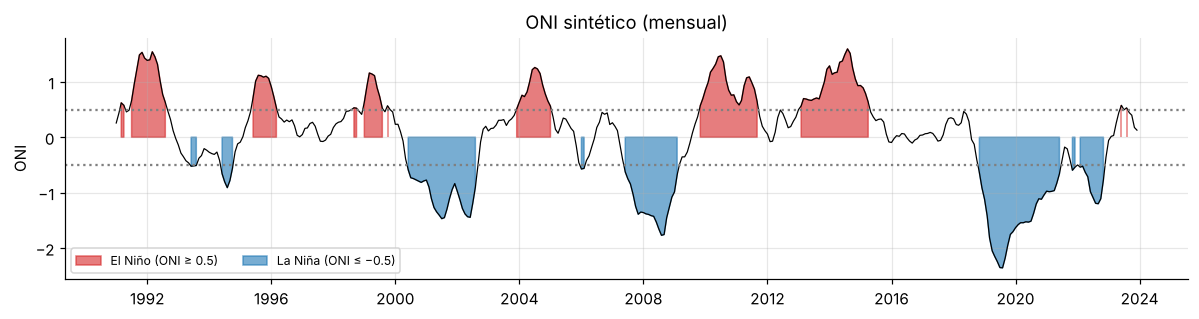

In [3]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.fill_between(oni.index, oni, 0, where=oni >= 0.5, color="tab:red",  alpha=.6, label="El Niño (ONI ≥ 0.5)")
ax.fill_between(oni.index, oni, 0, where=oni <= -0.5, color="tab:blue", alpha=.6, label="La Niña (ONI ≤ −0.5)")
ax.plot(oni, color="k", lw=.8)
ax.axhline(0.5, ls=":", c="gray"); ax.axhline(-0.5, ls=":", c="gray")
ax.set(title="ONI sintético (mensual)", ylabel="ONI"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

### 2.2 Tres "descargas" con formatos, unidades y defectos distintos
Cada fuente se parece a su versión real en lo que importa para el procesamiento:

| Fuente | Tipo | Formato simulado | Defectos simulados |
|---|---|---|---|
| **IDEAM** | Estación puntual | `FECHA` dd/mm/aaaa, `TMEDIA` °C, `PRECIP` mm, `HRMEDIA` % | Vacíos (aleatorios, en bloques y uno de ~8 meses), centinela `-999`, valores atípicos, **bloque en °F**, fechas duplicadas |
| **NASA POWER** | Satélite / reanálisis (celda gruesa) | `DATE` aaaammdd, `T2M`, `PRECTOTCORR`, `RH2M` | Completo, pero con **sesgo cálido**, lluvia suavizada y sobrestimada |
| **ERA5** | Reanálisis | `valid_date` ISO, `t2m` en **K**, `tp` en **m**, `rh2m` | Sesgo frío, tendencia algo menor, **llovizna espuria** y sobreestimación de lluvia |

Se escriben como **archivos CSV** y luego se vuelven a leer, igual que se haría con descargas reales.

In [4]:
# ===================== IDEAM (estación) =====================
ideam = pd.DataFrame({
    "FECHA":   fechas.strftime("%d/%m/%Y"),
    "TMEDIA":  (T + rng.normal(0, 0.25, n_d)).round(1),
    "PRECIP":  np.round(np.clip(P * rng.normal(1.0, 0.05, n_d), 0, None), 1),
    "HRMEDIA": np.round(np.clip(HR + rng.normal(0, 1.5, n_d), 0, 100), 0),
})
cols_i = ["TMEDIA", "PRECIP", "HRMEDIA"]

# 1) Bloque con temperatura en °F (error de unidades)
m = (fechas >= "2015-06-01") & (fechas <= "2015-09-30")
ideam.loc[m, "TMEDIA"] = (ideam.loc[m, "TMEDIA"] * 9/5 + 32).round(1)

# 2) Vacíos: aleatorios, en bloques y uno largo (≈ 8 meses en 2001)
for c, p in zip(cols_i, [0.03, 0.04, 0.03]):
    ideam.loc[rng.random(n_d) < p, c] = np.nan
for _ in range(10):
    i, L = rng.integers(0, n_d - 60), rng.integers(4, 20)
    ideam.loc[i:i+L, cols_i] = np.nan
i0 = np.flatnonzero(fechas >= "2001-03-01")[0]
i1 = np.flatnonzero(fechas >  "2001-10-31")[0]
ideam.loc[i0:i1, cols_i] = np.nan

# 3) Código centinela -999
for c in cols_i:
    ideam.loc[rng.choice(n_d, 12, replace=False), c] = -999

# 4) Valores atípicos
idx = rng.choice(n_d, 6, replace=False); ideam.loc[idx, "TMEDIA"] += rng.choice([-7, 7], 6)       # sutiles
idx = rng.choice(n_d, 3, replace=False); ideam.loc[idx, "TMEDIA"] = [41.0, 3.0, 47.0]             # imposibles
idx = rng.choice(n_d, 6, replace=False); ideam.loc[idx, "PRECIP"] = rng.uniform(450, 900, 6).round(1)
idx = rng.choice(n_d, 3, replace=False); ideam.loc[idx, "PRECIP"] = -rng.uniform(1, 10, 3).round(1)
idx = rng.choice(n_d, 6, replace=False); ideam.loc[idx, "HRMEDIA"] = rng.uniform(101, 130, 6).round(0)

# 5) Filas duplicadas
ideam = pd.concat([ideam, ideam.sample(15, random_state=SEED)]).sort_index(kind="stable").reset_index(drop=True)
ideam.to_csv(DIR_DATOS / "ideam_estacion.csv", index=False)

# ===================== NASA POWER =====================
P_suave = pd.Series(P).rolling(3, center=True, min_periods=1).mean().to_numpy()
nasa = pd.DataFrame({
    "DATE":        fechas.strftime("%Y%m%d").astype(int),
    "T2M":         T + 0.4 + rng.normal(0, 0.35, n_d),
    "PRECTOTCORR": (0.7*P + 0.3*P_suave) * 1.10 * rng.lognormal(0, 0.25, n_d),
    "RH2M":        (HR + 2.0 + rng.normal(0, 2.0, n_d)).clip(0, 100),
}).round(2)
nasa.to_csv(DIR_DATOS / "nasa_power.csv", index=False)

# ===================== ERA5 =====================
llovizna = np.where(rng.random(n_d) < 0.4, rng.gamma(0.5, 0.8, n_d), 0.0)
tp_mm = (P_suave * 1.20 + llovizna) * rng.lognormal(0, 0.3, n_d)
era5 = pd.DataFrame({
    "valid_date": fechas.strftime("%Y-%m-%d"),
    "t2m":  (T - 0.9 - 0.008*anios + rng.normal(0, 0.5, n_d) + 273.15).round(2),   # Kelvin
    "tp":   (tp_mm / 1000).round(6),                                               # metros
    "rh2m": (HR - 3.0 + rng.normal(0, 3.0, n_d)).clip(0, 100).round(1),
})
era5.to_csv(DIR_DATOS / "era5_celda.csv", index=False)

print("Archivos escritos en", DIR_DATOS)
ideam.iloc[[0, 1, 2, 5000, 5001]]

Archivos escritos en datos_sinteticos


,FECHA,TMEDIA,PRECIP,HRMEDIA
0,01/01/1991,28.80,0.00,NaN
1,02/01/1991,27.80,NaN,73.00
2,03/01/1991,28.50,0.00,77.00
5000,02/09/2004,27.80,6.50,84.00
5001,03/09/2004,27.60,27.20,86.00


## 3. Lectura, armonización e inventario de fuentes (Objetivo específico 1)
Cada fuente se lee con su propio *loader*, que la lleva a un **esquema común**: índice `fecha` y columnas
`temp_c` (°C), `precip_mm` (mm/día) y `hr_pct` (%).

> **Para usar datos reales:** basta con reemplazar las rutas de los CSV y ajustar estos tres *loaders*;
> el resto del cuaderno no cambia.

In [5]:
def cargar_ideam(ruta):
    d = pd.read_csv(ruta)
    d["fecha"] = pd.to_datetime(d["FECHA"], format="%d/%m/%Y")
    d = d.rename(columns={"TMEDIA": "temp_c", "PRECIP": "precip_mm", "HRMEDIA": "hr_pct"})
    return d.set_index("fecha")[COLS]

def cargar_nasa(ruta):
    d = pd.read_csv(ruta)
    d["fecha"] = pd.to_datetime(d["DATE"].astype(str), format="%Y%m%d")
    d = d.rename(columns={"T2M": "temp_c", "PRECTOTCORR": "precip_mm", "RH2M": "hr_pct"})
    return d.set_index("fecha")[COLS]

def cargar_era5(ruta):
    d = pd.read_csv(ruta)
    d["fecha"] = pd.to_datetime(d["valid_date"], format="%Y-%m-%d")
    d["temp_c"] = d["t2m"] - 273.15          # K → °C
    d["precip_mm"] = d["tp"] * 1000.0        # m → mm
    d = d.rename(columns={"rh2m": "hr_pct"})
    return d.set_index("fecha")[COLS]

crudos = {
    "IDEAM":      cargar_ideam(DIR_DATOS / "ideam_estacion.csv"),
    "NASA POWER": cargar_nasa(DIR_DATOS / "nasa_power.csv"),
    "ERA5":       cargar_era5(DIR_DATOS / "era5_celda.csv"),
}

meta = {
    "IDEAM":      ("Estación (puntual)",      "Diaria", "Puntual"),
    "NASA POWER": ("Satélite + reanálisis",   "Diaria", "≈ 0.5° × 0.625°"),
    "ERA5":       ("Reanálisis",              "Horaria → diaria", "≈ 0.25°"),
}
inv = []
for nom, d in crudos.items():
    nul = d.isna().mean() * 100
    cent = (d <= -900).mean() * 100
    inv.append({
        "Fuente": nom, "Tipo": meta[nom][0], "Res. temporal": meta[nom][1], "Res. espacial": meta[nom][2],
        "Inicio": d.index.min().date(), "Fin": d.index.max().date(),
        "Filas": len(d), "Fechas duplicadas": int(d.index.duplicated().sum()),
        "% vacío T": nul["temp_c"] + cent["temp_c"], "% vacío P": nul["precip_mm"] + cent["precip_mm"],
        "% vacío HR": nul["hr_pct"] + cent["hr_pct"],
    })
pd.DataFrame(inv).set_index("Fuente").T

Fuente,IDEAM,NASA POWER,ERA5
Tipo,Estación (puntual),Satélite + reanálisis,Reanálisis
Res. temporal,Diaria,Diaria,Horaria → diaria
Res. espacial,Puntual,≈ 0.5° × 0.625°,≈ 0.25°
Inicio,1991-01-01,1991-01-01,1991-01-01
Fin,2023-12-31,2023-12-31,2023-12-31
Filas,12068,12053,12053
Fechas duplicadas,15,0,0
% vacío T,6.12,0.00,0.00
% vacío P,6.81,0.00,0.00
% vacío HR,5.78,0.00,0.00


## 4. Control de calidad documentado (Objetivo específico 2)

Un **único** protocolo, aplicado igual a las tres fuentes, que deja constancia de cuántos datos se tocan en cada paso:

1. Eliminar fechas **duplicadas** y reindexar a un calendario diario completo (los días ausentes pasan a `NaN`).
2. Convertir códigos **centinela** (`-999`) en `NaN`.
3. Detectar y corregir **unidades** (temperatura > 50 → está en °F → se convierte a °C).
4. **Rangos físicos** plausibles para la región.
5. **Atípicos estadísticos** (temperatura y humedad): z robusto con mediana y MAD sobre la anomalía respecto a la climatología mensual.
6. **Faltantes:** interpolación lineal **solo en huecos ≤ 3 días** (temperatura y humedad). La precipitación **no se imputa**
   (rellenarla inventaría lluvia); los huecos largos se **excluyen**.

In [6]:
RANGOS = {"temp_c": (15, 38), "precip_mm": (0, 400), "hr_pct": (0, 100)}

def z_robusto_mensual(s):
    '''z robusto (mediana/MAD) de la anomalía respecto a la mediana de cada mes calendario.'''
    mes_ = s.index.month
    res = s - s.groupby(mes_).transform("median")
    mad = res.abs().groupby(mes_).transform("median")
    return 0.6745 * res / mad

def interpolar_huecos_cortos(s, max_len=3):
    '''Interpola solo huecos internos de a lo sumo max_len días consecutivos.'''
    es_nan = s.isna()
    grupo  = (es_nan != es_nan.shift()).cumsum()
    largo  = es_nan.groupby(grupo).transform("sum")
    relleno = s.interpolate(limit_area="inside")
    return s.where(~(es_nan & (largo <= max_len)), relleno)

PASOS = ["Filas duplicadas eliminadas", "Días ausentes en el calendario", "Vacíos originales (NaN)",
         "Centinelas (-999) → NaN", "Temperatura en °F → °C", "Fuera de rango físico → NaN",
         "Atípicos robustos (|z|>4.5) → NaN", "Huecos ≤3 d interpolados"]

def control_calidad(d, z_umbral=4.5, max_hueco=3):
    log = pd.DataFrame(0, index=PASOS, columns=COLS, dtype=float)

    dup = int(d.index.duplicated().sum())
    d = d[~d.index.duplicated(keep="first")]
    log.loc[PASOS[0], :] = dup

    ausentes = len(fechas) - len(d)
    d = d.reindex(fechas)
    log.loc[PASOS[1], :] = ausentes
    log.loc[PASOS[2], :] = d.isna().sum()

    cent = d <= -900
    log.loc[PASOS[3], :] = cent.sum()
    d = d.mask(cent)

    f = d["temp_c"] > 50
    log.loc[PASOS[4], "temp_c"] = f.sum()
    d.loc[f, "temp_c"] = (d.loc[f, "temp_c"] - 32) * 5/9

    for c, (lo, hi) in RANGOS.items():
        fuera = (d[c] < lo) | (d[c] > hi)
        log.loc[PASOS[5], c] = fuera.sum()
        d.loc[fuera, c] = np.nan

    for c in ["temp_c", "hr_pct"]:
        atip = z_robusto_mensual(d[c]).abs() > z_umbral
        log.loc[PASOS[6], c] = atip.sum()
        d.loc[atip, c] = np.nan
        antes = d[c].isna().sum()
        d[c] = interpolar_huecos_cortos(d[c], max_hueco)
        log.loc[PASOS[7], c] = antes - d[c].isna().sum()

    return d, log

limpios, logs = {}, {}
for nom, d in crudos.items():
    limpios[nom], logs[nom] = control_calidad(d)

print("Bitácora de control de calidad — IDEAM (número de registros afectados)")
logs["IDEAM"]

Bitácora de control de calidad — IDEAM (número de registros afectados)


,temp_c,precip_mm,hr_pct
Filas duplicadas eliminadas,15.00,15.00,15.00
Días ausentes en el calendario,0.00,0.00,0.00
Vacíos originales (NaN),724.00,807.00,684.00
Centinelas (-999) → NaN,12.00,12.00,12.00
Temperatura en °F → °C,118.00,0.00,0.00
Fuera de rango físico → NaN,3.00,9.00,6.00
Atípicos robustos (|z|>4.5) → NaN,6.00,0.00,2.00
Huecos ≤3 d interpolados,390.00,0.00,347.00


In [7]:
resumen_qc = pd.concat({nom: lg.sum(axis=1) for nom, lg in logs.items()}, axis=1).drop(index=PASOS[2:3])
print("Registros afectados por paso (suma de las 3 variables)")
display(resumen_qc)

faltante_final = pd.DataFrame({nom: d.isna().mean() * 100 for nom, d in limpios.items()})
print("\n% de días sin dato después del control de calidad")
display(faltante_final)

Registros afectados por paso (suma de las 3 variables)


,IDEAM,NASA POWER,ERA5
Filas duplicadas eliminadas,45.00,0.00,0.00
Días ausentes en el calendario,0.00,0.00,0.00
Centinelas (-999) → NaN,36.00,0.00,0.00
Temperatura en °F → °C,118.00,0.00,0.00
Fuera de rango físico → NaN,18.00,0.00,0.00
Atípicos robustos (|z|>4.5) → NaN,8.00,1.00,0.00
Huecos ≤3 d interpolados,737.00,1.00,0.00



% de días sin dato después del control de calidad


,IDEAM,NASA POWER,ERA5
temp_c,2.95,0.00,0.00
precip_mm,6.87,0.00,0.00
hr_pct,2.96,0.00,0.00


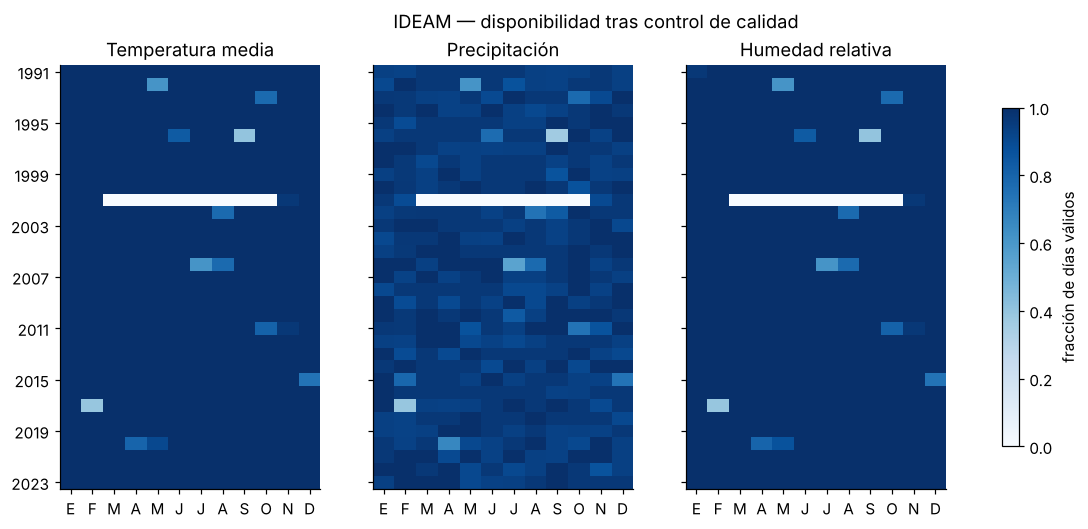

In [8]:
# Disponibilidad de datos IDEAM tras el control de calidad (fracción de días válidos por año × mes)
fig, axs = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
d = limpios["IDEAM"]
for ax, c in zip(axs, COLS):
    disp = d[c].notna().groupby([d.index.year, d.index.month]).mean().unstack()
    im = ax.imshow(disp.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(12)); ax.set_xticklabels(list("EFMAMJJASOND"))
    ax.set_yticks(range(0, len(disp), 4)); ax.set_yticklabels(disp.index[::4])
    ax.set_title(VARS[c][0]); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=.8, label="fracción de días válidos")
fig.suptitle("IDEAM — disponibilidad tras control de calidad", y=.98)
plt.show()

### 4.1 Agregación mensual con criterio de completitud
Un mes se acepta solo si tiene **≥ 80 % de días válidos**. Para la precipitación se escala el promedio de los días
disponibles a los días del mes (`media × días`) para no subestimar meses con pocos faltantes.

In [9]:
def mensualizar(d, min_frac=0.80):
    cnt  = d.resample("MS").count()
    dias = d.resample("MS").size()
    m = pd.DataFrame({
        "temp_c":    d["temp_c"].resample("MS").mean(),
        "precip_mm": d["precip_mm"].resample("MS").mean() * dias,
        "hr_pct":    d["hr_pct"].resample("MS").mean(),
    })
    ok = cnt.ge(dias * min_frac, axis=0)
    return m.where(ok)

mens = {nom: mensualizar(d) for nom, d in limpios.items()}
mens_verdad = mensualizar(verdad)           # solo para validar al final

print("Meses sin dato (de 396):")
pd.DataFrame({nom: m.isna().sum() for nom, m in mens.items()})

Meses sin dato (de 396):


,IDEAM,NASA POWER,ERA5
temp_c,16,0,0
precip_mm,20,0,0
hr_pct,16,0,0


## 5. Análisis descriptivo (Objetivo específico 3)

### 5.1 Estadísticos básicos (series mensuales)

In [10]:
desc = pd.concat({nom: m.describe().T[["count", "mean", "std", "min", "50%", "max"]]
                  for nom, m in mens.items()})
desc.index.names = ["Fuente", "Variable"]
desc

count   mean    std   min    50%    max
Fuente     Variable                                          
IDEAM      temp_c    380.00  28.05   0.63 26.40  28.06  29.62
           precip_mm 376.00 210.83 109.16 10.52 211.27 597.23
           hr_pct    380.00  81.35   2.73 75.00  80.94  88.34
NASA POWER temp_c    396.00  28.43   0.64 26.89  28.42  30.07
           precip_mm 396.00 239.80 122.79 19.95 241.94 596.13
           hr_pct    396.00  83.43   2.77 77.04  82.98  90.54
ERA5       temp_c    396.00  26.99   0.63 25.29  27.01  28.54
           precip_mm 396.00 271.91 135.34 30.49 272.31 755.01
           hr_pct    396.00  78.47   2.84 71.95  78.00  86.56

### 5.2 Climatología mensual
Promedio de cada mes calendario sobre todo el periodo. Permite ver el régimen **bimodal** de lluvia y, a la vez,
los **sesgos** característicos de cada fuente.

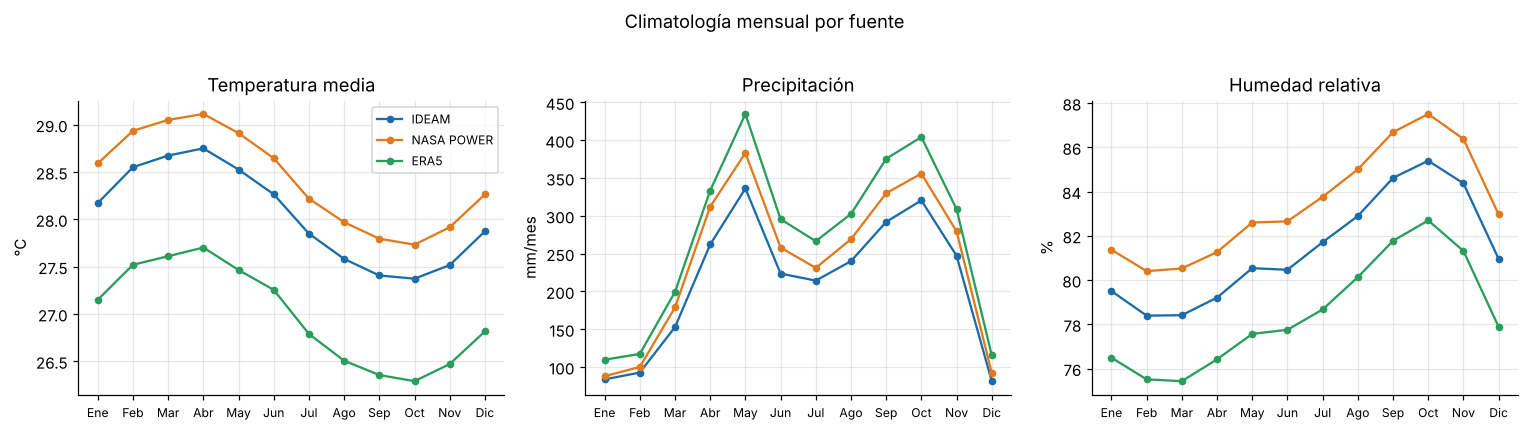

In [11]:
nombres_mes = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axs, COLS):
    for nom, m in mens.items():
        clim = m[c].groupby(m.index.month).mean()
        ax.plot(range(1, 13), clim.values, marker="o", ms=4, color=COLORES[nom], label=nom)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(nombres_mes, fontsize=8)
    ax.set(title=VARS[c][0], ylabel=VARS[c][1])
axs[0].legend(fontsize=8)
fig.suptitle("Climatología mensual por fuente", y=1.02)
plt.tight_layout(); plt.show()

### 5.3 Anomalías mensuales
Anomalía = valor mensual − climatología de ese mes. Elimina el ciclo anual y deja la señal interanual
(es la base para las correlaciones con el ONI).

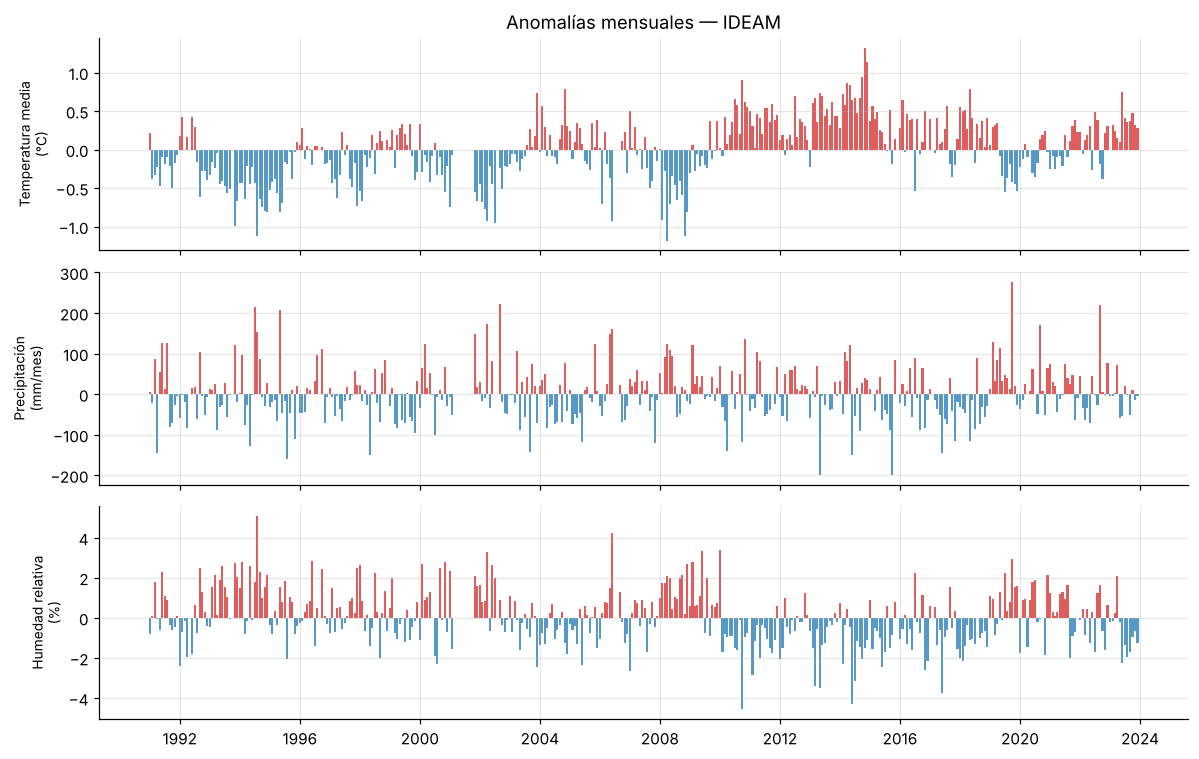

In [12]:
def anomalias(m):
    return m - m.groupby(m.index.month).transform("mean")

anom = {nom: anomalias(m) for nom, m in mens.items()}

fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, c in zip(axs, COLS):
    a = anom["IDEAM"][c]
    ax.bar(a.index, a.values, width=25, color=np.where(a >= 0, "tab:red", "tab:blue"), alpha=.75)
    ax.set_ylabel(f"{VARS[c][0]}\n({VARS[c][1]})", fontsize=9)
axs[0].set_title("Anomalías mensuales — IDEAM")
plt.tight_layout(); plt.show()

### 5.4 Descomposición estacional clásica (aditiva)
Implementada a mano con pandas: **tendencia** = media móvil centrada 2×12; **estacionalidad** = promedio por mes de la serie
sin tendencia (centrado en cero); **residuo** = lo que queda. Para la descomposición se interpolan linealmente los
meses faltantes *solo dentro de esta figura*.

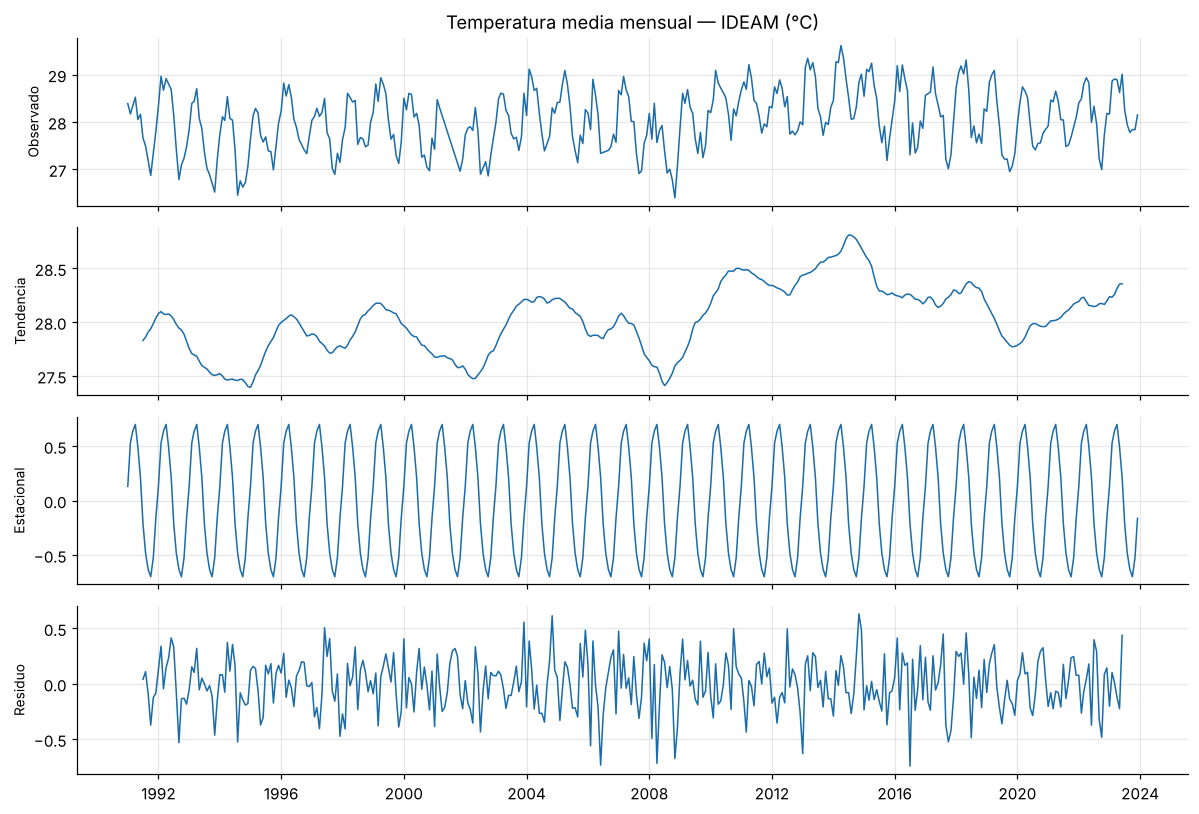

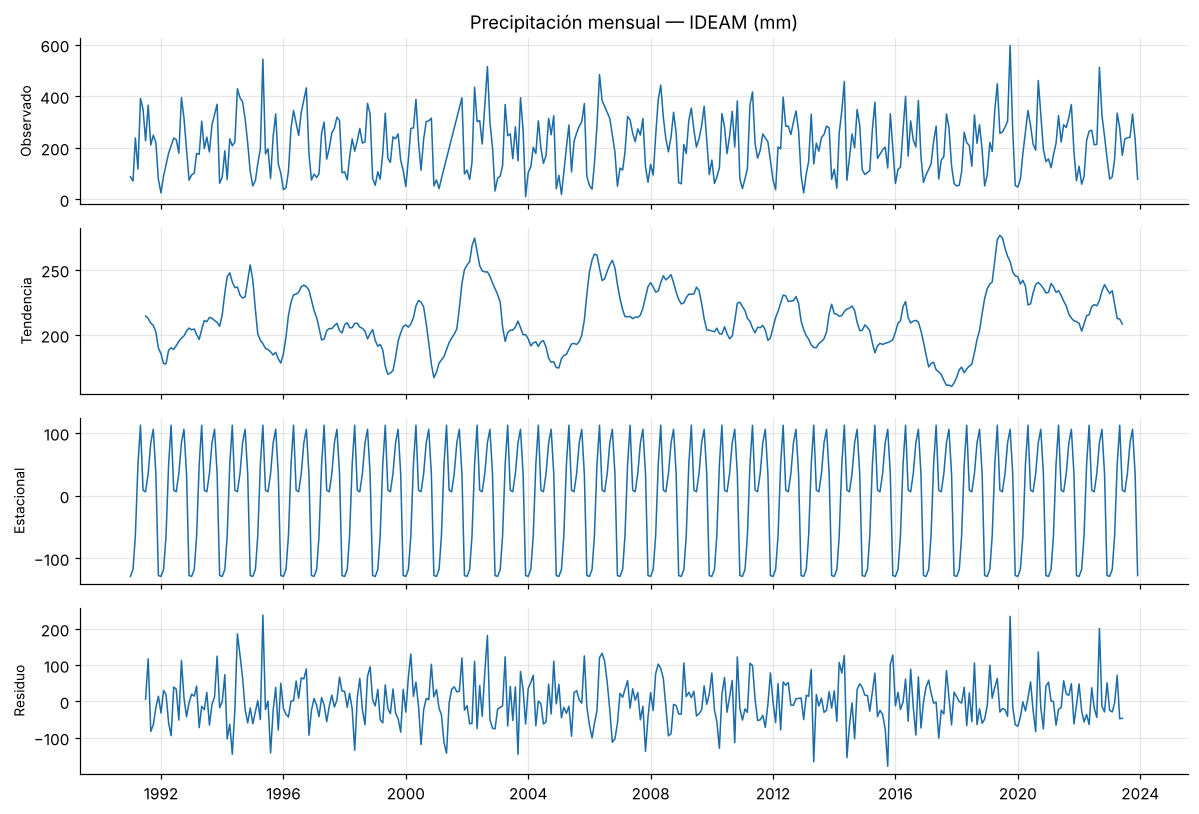

Fuerza de la estacionalidad (0–1) — Temperatura: 0.81 | Precipitación: 0.64


In [13]:
def descomposicion_clasica(s, periodo=12):
    s = s.interpolate(limit_area="inside")
    tend = s.rolling(periodo).mean().rolling(2).mean().shift(-periodo // 2)
    detr = s - tend
    idx = detr.groupby(detr.index.month).mean()
    idx = idx - idx.mean()
    est = pd.Series(s.index.month.map(idx).to_numpy(), index=s.index)
    return pd.DataFrame({"observado": s, "tendencia": tend, "estacional": est, "residuo": s - tend - est})

def graficar_descomposicion(s, titulo, color):
    comp = descomposicion_clasica(s)
    fig, axs = plt.subplots(4, 1, figsize=(11, 7.5), sharex=True)
    etiquetas = [("observado", "Observado"), ("tendencia", "Tendencia"),
                 ("estacional", "Estacional"), ("residuo", "Residuo")]
    for ax, (col, lab) in zip(axs, etiquetas):
        ax.plot(comp[col], color=color, lw=1)
        ax.set_ylabel(lab, fontsize=9)
    axs[0].set_title(titulo)
    plt.tight_layout(); plt.show()
    return comp

comp_T = graficar_descomposicion(mens["IDEAM"]["temp_c"],    "Temperatura media mensual — IDEAM (°C)", COLORES["IDEAM"])
comp_P = graficar_descomposicion(mens["IDEAM"]["precip_mm"], "Precipitación mensual — IDEAM (mm)",     COLORES["IDEAM"])

fuerza = lambda c: max(0, 1 - c["residuo"].var() / (c["residuo"] + c["estacional"]).var())
print(f"Fuerza de la estacionalidad (0–1) — Temperatura: {fuerza(comp_T.dropna()):.2f} | Precipitación: {fuerza(comp_P.dropna()):.2f}")

## 6. Tendencias: Mann-Kendall y pendiente de Sen (Objetivo específico 3)

- **Mann-Kendall**: prueba no paramétrica de tendencia monótona (con corrección por empates).
- **Pendiente de Sen**: mediana de todas las pendientes entre pares de puntos; robusta a atípicos. Se reporta con IC 95 %.

Se aplican a la **anomalía anual** (media de las anomalías mensuales; se exige ≥ 10 meses válidos en el año). Para la
precipitación, la anomalía anual se expresa en **mm/año**. Este paso evita que la ausencia de ciertos meses sesgue el
total anual.

In [14]:
def mann_kendall(x, alpha=0.05):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; n = len(x)
    s = sum(np.sign(x[k+1:] - x[k]).sum() for k in range(n - 1))
    _, cnt = np.unique(x, return_counts=True)
    var_s = (n*(n-1)*(2*n+5) - np.sum(cnt*(cnt-1)*(2*cnt+5))) / 18
    z = (s - np.sign(s)) / np.sqrt(var_s) if s != 0 else 0.0
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    tau = s / (n*(n-1)/2)
    return dict(n=n, S=s, tau=tau, z=z, p=p, var_s=var_s,
                tendencia="creciente" if (p < alpha and s > 0) else "decreciente" if (p < alpha and s < 0) else "sin tendencia")

def sen_slope(x, t, alpha=0.05):
    x = np.asarray(x, float); t = np.asarray(t, float)
    ok = ~np.isnan(x); x, t = x[ok], t[ok]
    i, j = np.triu_indices(len(x), 1)
    pend = np.sort((x[j] - x[i]) / (t[j] - t[i]))
    med = np.median(pend)
    N = len(pend)
    C = stats.norm.ppf(1 - alpha/2) * np.sqrt(mann_kendall(x)["var_s"])
    M1, M2 = int(np.floor((N - C) / 2)), int(np.ceil((N + C) / 2))
    lo, hi = pend[max(M1 - 1, 0)], pend[min(M2, N - 1)]
    interc = np.median(x - med * t)
    return med, lo, hi, interc

def anual_desde_anomalias(a, min_meses=10):
    g = a.groupby(a.index.year)
    out = g.mean().where(g.count() >= min_meses)
    out["precip_mm"] = out["precip_mm"] * 12        # anomalía total anual (mm/año)
    return out

anual = {nom: anual_desde_anomalias(a) for nom, a in anom.items()}

filas, sen_res = [], {}
for nom, an in anual.items():
    for c in COLS:
        mk = mann_kendall(an[c].values)
        sl, lo, hi, b = sen_slope(an[c].values, an.index.values)
        sen_res[(nom, c)] = (sl, b)
        filas.append({"Fuente": nom, "Variable": VARS[c][0], "n años": mk["n"], "tau": mk["tau"], "p-valor": mk["p"],
                      "Sen /década": sl * 10, "IC95 inf": lo * 10, "IC95 sup": hi * 10, "Veredicto": mk["tendencia"]})
tabla_tend = pd.DataFrame(filas)
unid = {"Temperatura media": "°C/déc", "Precipitación": "mm/déc", "Humedad relativa": "%/déc"}
tabla_tend["Unidad"] = tabla_tend["Variable"].map(unid)
tabla_tend

,Fuente,Variable,n años,tau,p-valor,Sen /década,IC95 inf,IC95 sup,Veredicto,Unidad
0,IDEAM,Temperatura media,32,0.40,0.00,0.17,0.07,0.29,creciente,°C/déc
1,IDEAM,Precipitación,32,0.03,0.81,19.36,-104.37,116.59,sin tendencia,mm/déc
2,IDEAM,Humedad relativa,32,-0.28,0.02,-0.37,-0.64,-0.07,decreciente,%/déc
3,NASA POWER,Temperatura media,33,0.39,0.00,0.18,0.08,0.28,creciente,°C/déc
4,NASA POWER,Precipitación,33,0.00,0.99,0.70,-124.96,100.55,sin tendencia,mm/déc
5,NASA POWER,Humedad relativa,33,-0.28,0.02,-0.34,-0.69,-0.04,decreciente,%/déc
6,ERA5,Temperatura media,33,0.20,0.10,0.09,-0.02,0.21,sin tendencia,°C/déc
7,ERA5,Precipitación,33,-0.02,0.89,-15.50,-165.32,127.84,sin tendencia,mm/déc
8,ERA5,Humedad relativa,33,-0.30,0.01,-0.40,-0.74,-0.10,decreciente,%/déc


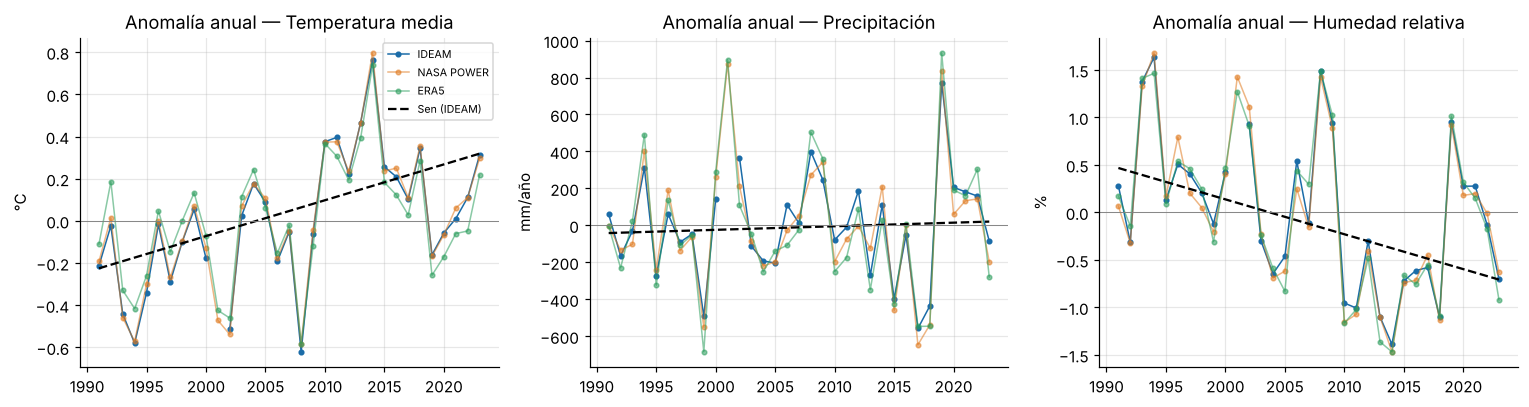

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axs, COLS):
    for nom, an in anual.items():
        ax.plot(an.index, an[c], marker="o", ms=3, lw=1, color=COLORES[nom], alpha=.55 if nom != "IDEAM" else 1, label=nom)
    sl, b = sen_res[("IDEAM", c)]
    yy = np.array([anual["IDEAM"].index.min(), anual["IDEAM"].index.max()])
    ax.plot(yy, b + sl * yy, "k--", lw=1.5, label="Sen (IDEAM)")
    ax.axhline(0, color="gray", lw=.6)
    u = "mm/año" if c == "precip_mm" else VARS[c][1]
    ax.set(title=f"Anomalía anual — {VARS[c][0]}", ylabel=u)
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Variabilidad interanual y ENSO (Objetivo específico 4)

### 7.1 Correlación con el ONI a distintos rezagos
Se correlaciona la anomalía mensual en el tiempo *t* con el ONI en *t − k* (k = 0…12 meses) mediante **Spearman**.

**Cuidado con la significancia:** tanto el ONI como las anomalías climáticas tienen fuerte autocorrelación, de modo que
el tamaño muestral *efectivo* es menor que *n*. Se usa la corrección  
$n_{ef} = n\,\dfrac{1 - r_{1x}\,r_{1y}}{1 + r_{1x}\,r_{1y}}$  
para calcular un p-valor más honesto.

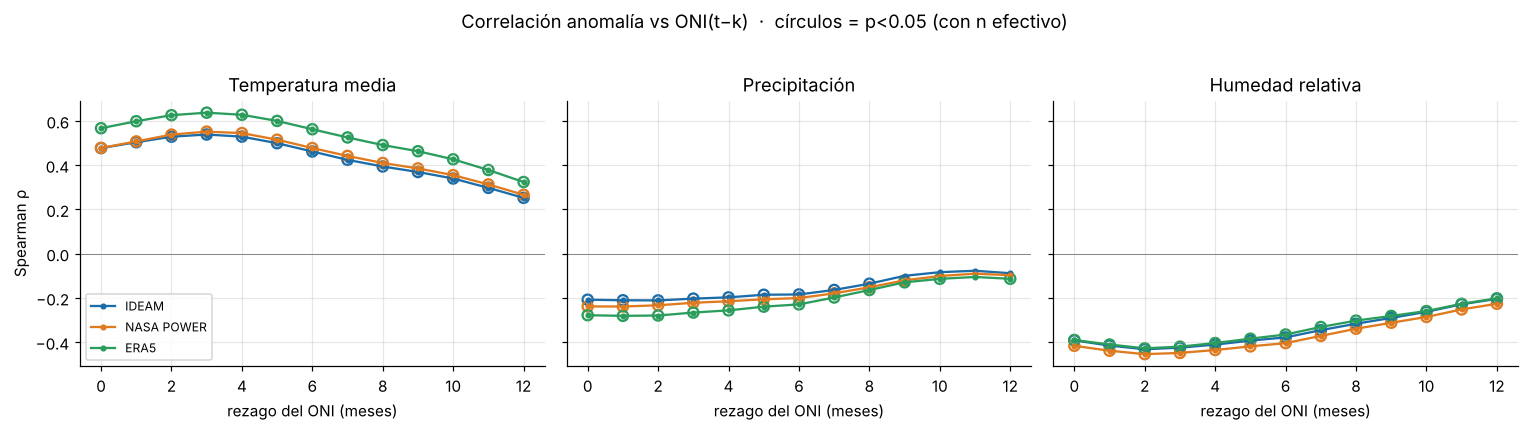

,fuente,var,rezago,rho,p,n_ef
0,ERA5,Humedad relativa,2,-0.43,0.00,231.65
1,ERA5,Precipitación,1,-0.28,0.00,351.42
2,ERA5,Temperatura media,3,0.64,0.00,106.96
3,IDEAM,Humedad relativa,2,-0.43,0.00,209.24
4,IDEAM,Precipitación,2,-0.21,0.00,331.71
5,IDEAM,Temperatura media,3,0.54,0.00,78.66
6,NASA POWER,Humedad relativa,2,-0.45,0.00,220.84
7,NASA POWER,Precipitación,1,-0.24,0.00,329.49
8,NASA POWER,Temperatura media,3,0.55,0.00,88.74


In [16]:
def corr_spearman_neff(x, y):
    d = pd.concat([x, y], axis=1).dropna()
    n = len(d)
    rho, _ = stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])
    r1x, r1y = d.iloc[:, 0].autocorr(1), d.iloc[:, 1].autocorr(1)
    n_ef = float(np.clip(n * (1 - r1x*r1y) / (1 + r1x*r1y), 4, n))
    t = rho * np.sqrt((n_ef - 2) / (1 - rho**2))
    p = 2 * stats.t.sf(abs(t), n_ef - 2)
    return rho, p, n, n_ef

REZAGOS = range(0, 13)
res_lag = []
for nom, a in anom.items():
    for c in COLS:
        for k in REZAGOS:
            rho, p, n, n_ef = corr_spearman_neff(a[c], oni.shift(k))
            res_lag.append(dict(fuente=nom, var=c, rezago=k, rho=rho, p=p, n=n, n_ef=n_ef))
res_lag = pd.DataFrame(res_lag)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, c in zip(axs, COLS):
    for nom in anom:
        s = res_lag.query("fuente == @nom and var == @c")
        ax.plot(s.rezago, s.rho, color=COLORES[nom], marker="o", ms=3, label=nom)
        sig = s[s.p < 0.05]
        ax.scatter(sig.rezago, sig.rho, s=45, facecolors="none", edgecolors=COLORES[nom], linewidths=1.5)
    ax.axhline(0, color="gray", lw=.6)
    ax.set(title=VARS[c][0], xlabel="rezago del ONI (meses)")
axs[0].set_ylabel("Spearman ρ"); axs[0].legend(fontsize=8)
fig.suptitle("Correlación anomalía vs ONI(t−k)  ·  círculos = p<0.05 (con n efectivo)", y=1.02)
plt.tight_layout(); plt.show()

mejor = (res_lag.loc[res_lag.groupby(["fuente", "var"])["rho"].apply(lambda s: s.abs().idxmax())]
         [["fuente", "var", "rezago", "rho", "p", "n_ef"]].reset_index(drop=True))
mejor["var"] = mejor["var"].map(lambda v: VARS[v][0])
mejor

### 7.2 Composites por fase del ENSO
Se clasifica cada mes según el ONI rezagado 3 meses (**El Niño** ≥ 0.5, **La Niña** ≤ −0.5, **Neutral** en medio) y se
comparan las anomalías con una prueba **Kruskal-Wallis**.

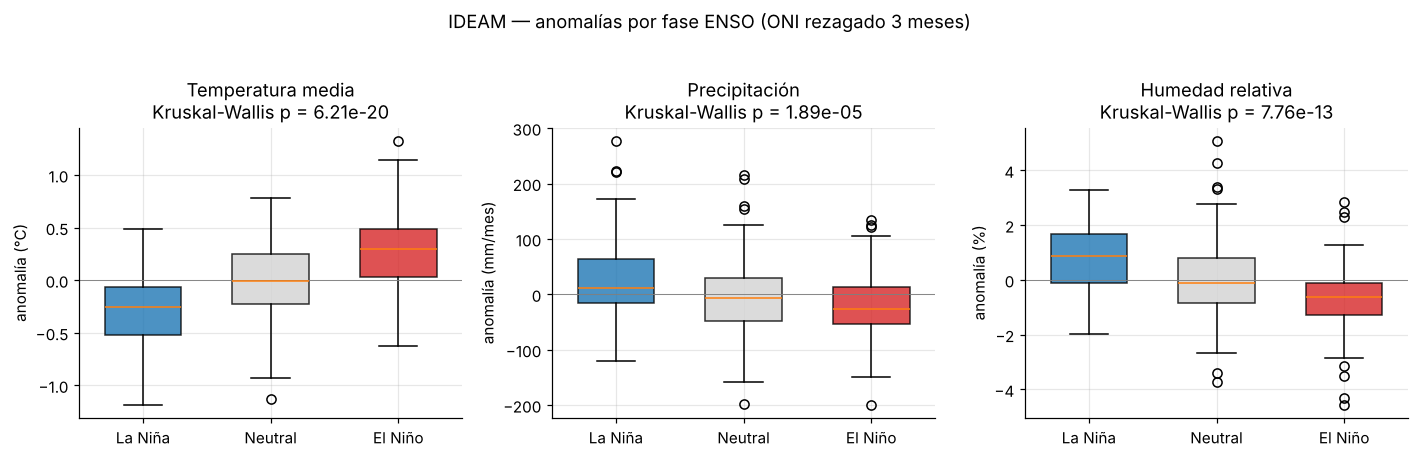

Meses por fase: {'Neutral': 188, 'El Niño': 103, 'La Niña': 102}


In [17]:
REZ_FASE = 3
fase = pd.cut(oni.shift(REZ_FASE), [-np.inf, -0.5, 0.5, np.inf], labels=["La Niña", "Neutral", "El Niño"])
colores_fase = {"La Niña": "tab:blue", "Neutral": "lightgray", "El Niño": "tab:red"}

fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, c in zip(axs, COLS):
    d = pd.DataFrame({"a": anom["IDEAM"][c], "fase": fase}).dropna()
    grupos = [d.loc[d.fase == f, "a"].values for f in ["La Niña", "Neutral", "El Niño"]]
    H, p = stats.kruskal(*grupos)
    bp = ax.boxplot(grupos, tick_labels=["La Niña", "Neutral", "El Niño"], patch_artist=True, widths=.6)
    for patch, f in zip(bp["boxes"], ["La Niña", "Neutral", "El Niño"]):
        patch.set_facecolor(colores_fase[f]); patch.set_alpha(.8)
    ax.axhline(0, color="gray", lw=.6)
    ax.set(title=f"{VARS[c][0]}\nKruskal-Wallis p = {p:.3g}", ylabel=f"anomalía ({VARS[c][1]})")
fig.suptitle(f"IDEAM — anomalías por fase ENSO (ONI rezagado {REZ_FASE} meses)", y=1.03)
plt.tight_layout(); plt.show()

print("Meses por fase:", fase.value_counts().to_dict())

## 8. Asociaciones entre variables (Objetivo específico 4)
Matriz de correlación de Spearman entre las anomalías mensuales de las tres variables y el ONI (rezagado 3 meses).

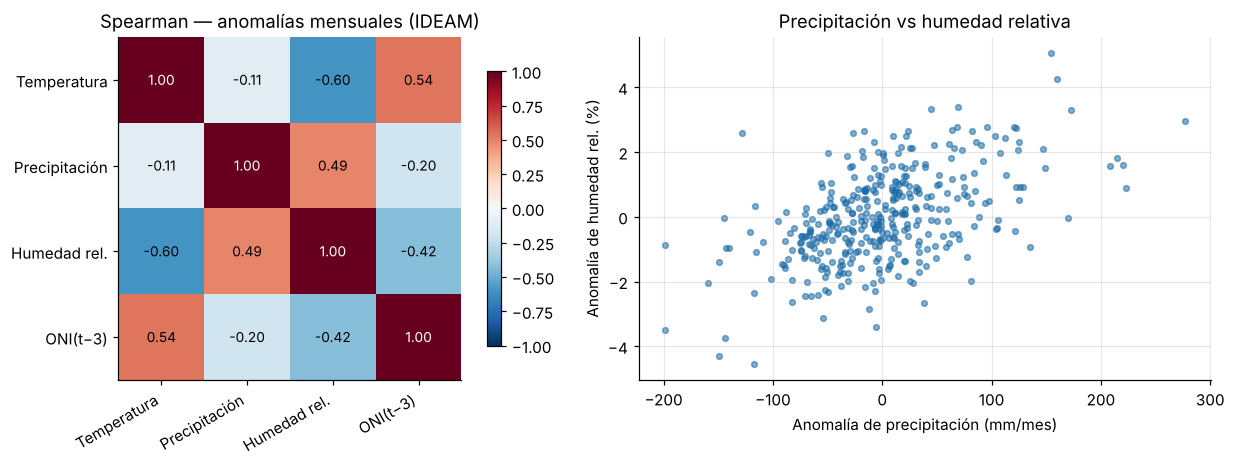

In [18]:
datos_corr = anom["IDEAM"].copy()
datos_corr["ONI(t−3)"] = oni.shift(3)
datos_corr.columns = ["Temperatura", "Precipitación", "Humedad rel.", "ONI(t−3)"]
corr = datos_corr.corr(method="spearman")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.1]})
im = axs[0].imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1); axs[0].grid(False)
axs[0].set_xticks(range(4)); axs[0].set_xticklabels(corr.columns, rotation=30, ha="right")
axs[0].set_yticks(range(4)); axs[0].set_yticklabels(corr.columns)
for i in range(4):
    for j in range(4):
        axs[0].text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center",
                    color="white" if abs(corr.values[i, j]) > .6 else "black", fontsize=9)
fig.colorbar(im, ax=axs[0], shrink=.8)
axs[0].set_title("Spearman — anomalías mensuales (IDEAM)")

d = datos_corr.dropna()
axs[1].scatter(d["Precipitación"], d["Humedad rel."], s=14, alpha=.55, color=COLORES["IDEAM"])
axs[1].set(xlabel="Anomalía de precipitación (mm/mes)", ylabel="Anomalía de humedad rel. (%)",
           title="Precipitación vs humedad relativa")
plt.tight_layout(); plt.show()

## 9. Comparación entre fuentes (Metodología)
Se toma la **estación IDEAM** como referencia y se evalúan NASA POWER y ERA5 con sesgo medio, RMSE, MAE y correlación
de Spearman, tanto para **valores** como para **anomalías**. La correlación de anomalías indica si la fuente
reproduce la *variabilidad* aunque tenga sesgo en el *nivel*.

In [19]:
def metricas(ref, x):
    d = pd.concat([ref, x], axis=1).dropna()
    r, y = d.iloc[:, 0], d.iloc[:, 1]
    dif = y - r
    return {"n meses": len(d), "Sesgo": dif.mean(), "RMSE": np.sqrt((dif**2).mean()), "MAE": dif.abs().mean(),
            "ρ valores": stats.spearmanr(r, y)[0],
            "ρ anomalías": stats.spearmanr(*pd.concat([anom["IDEAM"][c_g], anom[nom_g][c_g]], axis=1).dropna().T.values)[0]}

filas = []
for nom_g in ["NASA POWER", "ERA5"]:
    for c_g in COLS:
        m = metricas(mens["IDEAM"][c_g], mens[nom_g][c_g])
        filas.append({"Fuente": nom_g, "Variable": f"{VARS[c_g][0]} ({VARS[c_g][1]})", **m})
comparacion = pd.DataFrame(filas).set_index(["Fuente", "Variable"])
comparacion

n meses  Sesgo  RMSE   MAE  ρ valores  ρ anomalías
Fuente     Variable                                                                  
NASA POWER Temperatura media (°C)      380   0.40  0.40  0.40       0.99         0.98
           Precipitación (mm/mes)      376  25.81 37.75 27.83       0.98         0.93
           Humedad relativa (%)        380   2.01  2.06  2.01       0.98         0.94
ERA5       Temperatura media (°C)      380  -1.04  1.05  1.04       0.98         0.93
           Precipitación (mm/mes)      376  57.87 69.91 58.04       0.97         0.90
           Humedad relativa (%)        380  -2.95  3.01  2.95       0.98         0.91

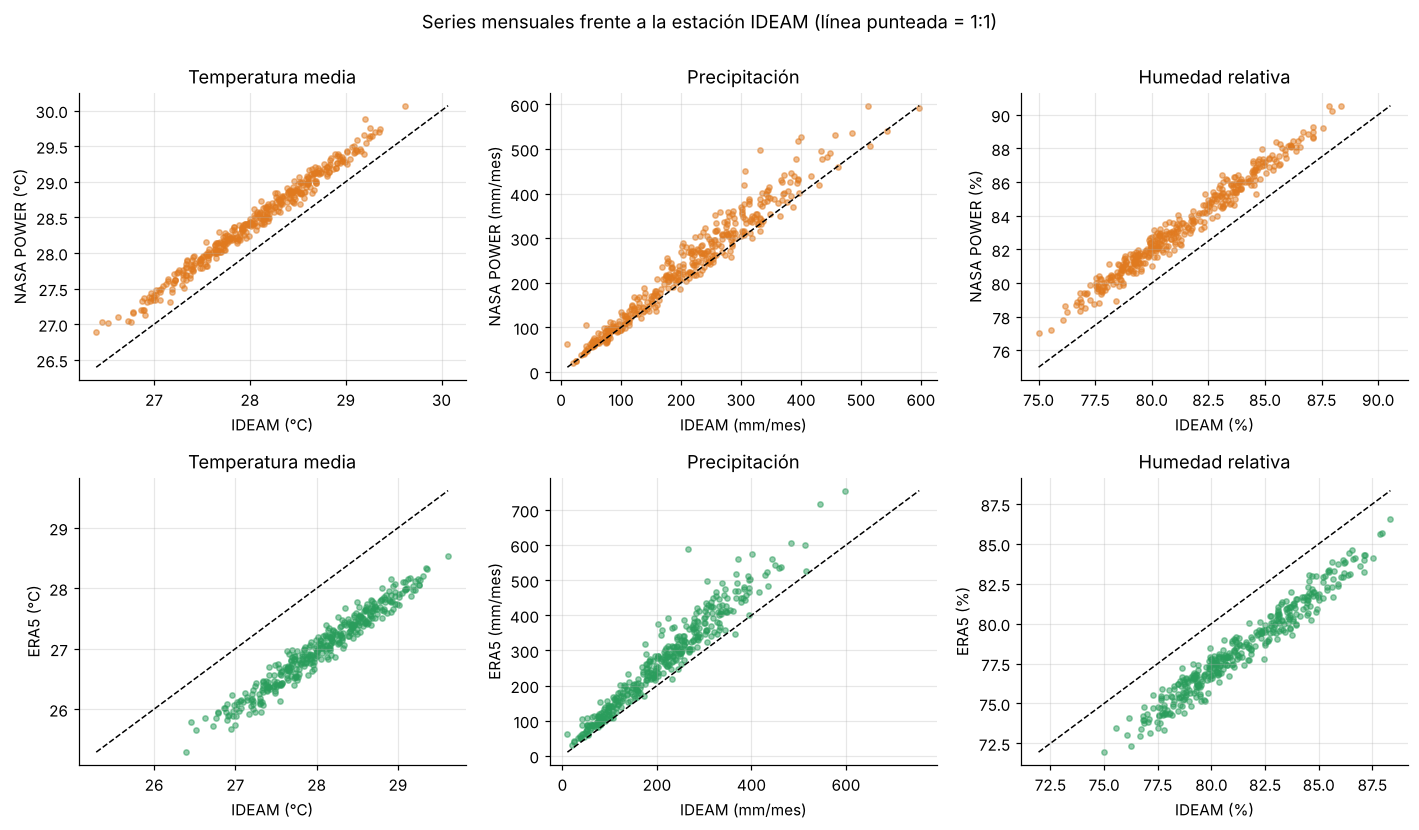

In [20]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7.5))
for i, nom in enumerate(["NASA POWER", "ERA5"]):
    for j, c in enumerate(COLS):
        d = pd.concat([mens["IDEAM"][c], mens[nom][c]], axis=1).dropna()
        ax = axs[i, j]
        ax.scatter(d.iloc[:, 0], d.iloc[:, 1], s=12, alpha=.5, color=COLORES[nom])
        lo, hi = d.values.min(), d.values.max()
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        ax.set(xlabel=f"IDEAM ({VARS[c][1]})", ylabel=f"{nom} ({VARS[c][1]})", title=VARS[c][0])
fig.suptitle("Series mensuales frente a la estación IDEAM (línea punteada = 1:1)", y=1.00)
plt.tight_layout(); plt.show()

## 10. Validación: ¿el flujo de trabajo recupera lo que sembramos?
Esta sección **solo es posible con datos sintéticos**, porque conocemos la verdad. Se comparan los valores inyectados con
lo estimado por el procedimiento (usando la estación IDEAM, que es la fuente con más defectos).

- **Tendencia de temperatura:** sembrada +0.025 °C/año → **+0.25 °C/década** (ERA5 tiene un sesgo de deriva deliberado).
- **Tendencia de precipitación:** −0.2 %/año sobre 2 700 mm ≈ **−54 mm/década**.
- **Tendencia de humedad:** no se sembró directamente; es una consecuencia de la relación con la temperatura (≈ −0.45 %/década).
- **Rezagos ENSO:** temperatura 3 meses; precipitación 2 meses.

In [21]:
sembrado = {"temp_c": 0.025 * 10, "precip_mm": PARAMS["precip_anual"] * PARAMS["precip_tendencia_pct"] / 100 * 10,
            "hr_pct": -1.8 * 0.025 * 10}
rez_sembrado = {"temp_c": PARAMS["temp_enso_rezago"], "precip_mm": PARAMS["precip_enso_rezago"], "hr_pct": None}

# tendencia en la serie "verdad" (sin defectos) y en las fuentes
anual_verdad = anual_desde_anomalias(anomalias(mens_verdad))
unid_dec = {"temp_c": "°C/déc", "precip_mm": "mm/déc", "hr_pct": "%/déc"}
ic_ideam = tabla_tend.query("Fuente == 'IDEAM'").set_index("Variable")
filas = []
for c in COLS:
    sl_v, _, _, _ = sen_slope(anual_verdad[c].values, anual_verdad.index.values)
    lo, hi = ic_ideam.loc[VARS[c][0], ["IC95 inf", "IC95 sup"]]
    fila = {"Variable": f"{VARS[c][0]} ({unid_dec[c]})",
            "Sembrado (aprox.)": sembrado[c], "Serie verdadera": sl_v * 10}
    for nom in mens:
        fila[nom] = sen_res[(nom, c)][0] * 10
    fila["IC95 IDEAM"] = f"[{lo:.2f}, {hi:.2f}]"
    fila["¿Sembrado dentro del IC95?"] = "sí" if lo <= sembrado[c] <= hi else "no"
    filas.append(fila)
rec_tend = pd.DataFrame(filas).set_index("Variable")
print("Pendiente de Sen por década: valor sembrado vs. estimado")
display(rec_tend)

rho_v = []
for c in ["temp_c", "precip_mm"]:
    for nom in mens:
        s = res_lag.query("fuente == @nom and var == @c")
        k = int(s.loc[s.rho.abs().idxmax(), "rezago"])
        rho_v.append({"Variable": VARS[c][0], "Fuente": nom, "Rezago sembrado": rez_sembrado[c], "Rezago estimado": k})
print("\nRezago ENSO: sembrado vs. estimado")
pd.DataFrame(rho_v)

Pendiente de Sen por década: valor sembrado vs. estimado


,Sembrado (aprox.),Serie verdadera,IDEAM,NASA POWER,ERA5,IC95 IDEAM,¿Sembrado dentro del IC95?
Variable,,,,,,,
Temperatura media (°C/déc),0.25,0.18,0.17,0.18,0.09,"[0.07, 0.29]",sí
Precipitación (mm/déc),-54.00,-2.03,19.36,0.70,-15.50,"[-104.37, 116.59]",sí
Humedad relativa (%/déc),-0.45,-0.39,-0.37,-0.34,-0.40,"[-0.64, -0.07]",sí



Rezago ENSO: sembrado vs. estimado


,Variable,Fuente,Rezago sembrado,Rezago estimado
0,Temperatura media,IDEAM,3,3
1,Temperatura media,NASA POWER,3,3
2,Temperatura media,ERA5,3,3
3,Precipitación,IDEAM,2,2
4,Precipitación,NASA POWER,2,1
5,Precipitación,ERA5,2,1


## 11. Lectura de resultados
Los números exactos dependen de la semilla; lo que se busca ilustrar es el **comportamiento del procedimiento**:

- **Control de calidad.** Los defectos de la estación (centinelas, °F, duplicados, atípicos, vacíos) se detectan y quedan
  *documentados* en la bitácora. Sin la corrección de °F o sin quitar los valores imposibles, las tendencias y correlaciones
  quedarían distorsionadas.
- **Estacionalidad.** La precipitación muestra un ciclo bimodal muy marcado (cientos de mm de amplitud). La temperatura tiene un
  ciclo de apenas décimas de grado, pero muy regular, por lo que su índice de fuerza estacional puede resultar alto; en
  cambio la lluvia, con más ruido interanual, tiende a mostrar un índice menor.
- **Tendencias.** Una señal pequeña (la de precipitación, −0.2 %/año) puede quedar **no significativa** frente a la enorme
  variabilidad interanual: *ausencia de significancia ≠ ausencia de tendencia*. Con 33 años, la potencia de la prueba es
  limitada. La tabla de la sección 10 lo verifica: el valor sembrado cae dentro del IC95 % aunque el IC sea muy ancho.
- **ENSO.** El rezago de máxima correlación debería aproximarse al sembrado, y el signo debe ser positivo para temperatura y
  negativo para precipitación. Usar el tamaño muestral efectivo evita sobreestimar la significancia.
- **Fuentes.** NASA POWER y ERA5 reproducen bien la *variabilidad* (correlación de anomalías alta) pero con **sesgos de nivel**
  (temperatura, lluvia) y diferencias en la tendencia: justo el motivo para compararlas con estaciones antes de usarlas.

### Limitaciones de la simulación
- La "verdad" es un modelo sencillo: no incluye ciclo diurno, MJO, eventos extremos organizados ni heterogeneidad espacial.
- Los errores de las fuentes son estacionarios y bien comportados; los reales suelen cambiar con la red de observación y el
  producto asimilado.
- Los defectos de la estación son los *esperables*, no un inventario de los reales del IDEAM.

## 12. Reproducibilidad (Objetivo específico 5)
Se exportan los datos depurados y las tablas de resultados, y se registra el entorno de ejecución.

In [22]:
for nom, m in mens.items():
    m.to_csv(DIR_SALIDAS / f"mensual_{nom.lower().replace(' ', '_')}.csv", index_label="fecha")
oni.to_csv(DIR_SALIDAS / "oni_sintetico.csv", index_label="fecha")
tabla_tend.to_csv(DIR_SALIDAS / "tendencias_mann_kendall_sen.csv", index=False)
mejor.to_csv(DIR_SALIDAS / "enso_mejor_rezago.csv", index=False)
comparacion.to_csv(DIR_SALIDAS / "comparacion_fuentes.csv")
pd.concat({n: l for n, l in logs.items()}).to_csv(DIR_SALIDAS / "bitacora_control_calidad.csv")

print("Semilla:", SEED)
print("Python :", sys.version.split()[0], "|", platform.platform())
for lib in (np, pd, __import__("scipy"), __import__("matplotlib")):
    print(f"{lib.__name__:<11}", lib.__version__)
print("\nArchivos en", DIR_SALIDAS, ":")
for f in sorted(DIR_SALIDAS.iterdir()):
    print("  ", f.name)

Semilla: 2024
Python : 3.12.3 | Linux-6.18.44-fc-v338-x86_64-with-glibc2.39
numpy       2.5.4
pandas      3.0.6
scipy       1.18.1
matplotlib  3.11.2

Archivos en salidas :
   bitacora_control_calidad.csv
   comparacion_fuentes.csv
   enso_mejor_rezago.csv
   mensual_era5.csv
   mensual_ideam.csv
   mensual_nasa_power.csv
   oni_sintetico.csv
   tendencias_mann_kendall_sen.csv


### Archivo de entorno sugerido (`requirements.txt`)
```
numpy>=1.26
pandas>=2.0
scipy>=1.11
matplotlib>=3.8
jupyter
```

### Siguientes pasos para pasar de la simulación a datos reales
1. Descargar series de **IDEAM** (DHIME), **NASA POWER** (API puntual) y **ERA5** (Copernicus CDS) para el Bajo Cauca.
2. Reemplazar los tres *loaders* de la sección 3 y los rangos físicos de la sección 4 si hiciera falta.
3. Reemplazar el ONI sintético por el **ONI oficial de NOAA/CPC**.
4. Ejecutar el cuaderno completo y versionar en un repositorio junto con `requirements.txt` (principios **FAIR**).